<a href="https://colab.research.google.com/github/mybenkhadda/GEMS---drivendata/blob/main/notebooks/colab/GEMS_DISCOVERY_GEOMOE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/mybenkhadda/GEMS---drivendata/blob/main/notebooks/colab/GEMS_DISCOVERY_GEOMOE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# GEMS discovery-first GeoMoE (code rev dgm.2-r1)

**One notebook, one CONFIG, run top to bottom.** `FAST_DIAGNOSTIC` measures candidate coverage first ([00]-[06]); `FULL` continues from the same cached artifacts into fusion, gating, deployment and export.

| | |
|---|---|
| Runtime | Colab **CPU**, High-RAM. No GPU, no neural network is trained. |
| Reference | **A_submitted_W2** = the frozen submitted W2 policy (public DTI 0.0942), one cell for every scenario |
| Outputs | `MyDrive/GEMS_2/outputs/discovery_geomoe/` |
| Code | `gems_bench/geomoe/` - docs `docs/geomoe/DISCOVERY_GEOMOE.md` |

Every stage checks its upstream stages: a failed / blocked dependency gives `BLOCKED_UPSTREAM` (compute) or `NOT_EVALUATED` (decision) and **no conclusion**. A failing test gives `TESTS_FAILED` and blocks candidates, modeling, selection and export. Cached results are reused only after validation (`REUSED_VALID_CACHE`).

**After a disconnect:** restart, run cells 1-2, then the stage cells again (finished units / stages are reused).

## 1 - Configuration (the only cell you edit)

`mode`: `FAST_DIAGNOSTIC` ([00]-[06] + integrity + reports) | `FULL` | `RESUME` (= FULL, cache forced). dgm.1 keys (`experts`, `experiments`, `export`) still work.

In [1]:
CONFIG = {
    'repo': 'mybenkhadda/GEMS---drivendata',
    'ref': 'main',                          # pin the pushed commit SHA for a reproducible run
    'drive_root': '/content/drive/MyDrive/GEMS_2',
    'local_root': '/content/gems_work',

    'mode': 'FULL',              # FAST_DIAGNOSTIC | FULL | RESUME
    'reuse_cached': True,
    'train_neural_models': False,           # True is refused

    'backfill_missing_g02': False,          # True: compute ONLY the missing G02 unit rasters (frozen G02 config)
    'dem': 'cached_only',                   # cached_only | off (never a DEM download)

    'run_synthetic_tests': True,            # self-tests + pytest, ENFORCED
    'strict_dependency_checks': True,

    'export_validated_candidate': True,
    'allow_exploratory_export': False,

    'save_all_outputs': True,
    'sync_to_drive': True,
    'overrides': {},                        # optional overrides of configs/geomoe/discovery_geomoe.yaml
}
PRIVATE_REPO = False
EXPECT = {'code_rev': 'dgm.2-r1', 'commit': None}   # set 'commit' to the pushed SHA

## 2 - Environment, Drive, frozen engine loader

In [2]:
from google.colab import drive
from pathlib import Path
import time

drive.flush_and_unmount()
time.sleep(3)
drive.mount('/content/drive', force_remount=True)

root = Path('/content/drive/MyDrive/GEMS_2')
ledger = root / 'environment/sync_ledger.json'

for attempt in range(1, 5):
    try:
        print("Drive root accessible:", root.is_dir())
        print("Sync ledger exists:", ledger.is_file())
        if ledger.is_file():
            print("Ledger size:", ledger.stat().st_size, "bytes")
        print("Drive connection: OK")
        break
    except (OSError, ConnectionError) as e:
        print(f"Drive access failed ({attempt}/4): {e}")
        if attempt == 4:
            raise RuntimeError(
                "Google Drive mount is unavailable. Restart the Colab runtime "
                "and mount Drive again before proceeding."
            ) from e
        time.sleep(3 * attempt)

Drive not mounted, so nothing to flush and unmount.
Mounted at /content/drive
Drive root accessible: True
Sync ledger exists: True
Ledger size: 1011497 bytes
Drive connection: OK


In [3]:
import base64, json, os, subprocess, sys
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')
CODE = '/content/GEMS'
REPO_URL = 'https://github.com/' + CONFIG['repo'] + '.git'

def _git_env():
    if not PRIVATE_REPO:
        return None
    from google.colab import userdata
    hdr = base64.b64encode(('x-access-token:' + (userdata.get('GITHUB_TOKEN') or '')).encode()).decode()
    return {**os.environ, 'GIT_CONFIG_COUNT': '1', 'GIT_CONFIG_KEY_0': 'http.https://github.com/.extraheader',
            'GIT_CONFIG_VALUE_0': 'AUTHORIZATION: basic ' + hdr}

def git(*args, auth=False, check=True):
    r = subprocess.run(['git', *args], capture_output=True, text=True, env=_git_env() if auth else None)
    if check and r.returncode:
        raise RuntimeError('git ' + ' '.join(args[:4]) + ' failed:\n' + r.stderr[-1500:])
    return r

if not Path(CODE, '.git').exists():
    git('clone', '-q', REPO_URL, CODE, auth=True)
git('-C', CODE, 'fetch', '-q', '--tags', 'origin', auth=True)
ref = CONFIG['ref']
if git('-C', CODE, 'rev-parse', '--verify', '-q', 'refs/remotes/origin/' + ref, check=False).returncode == 0:
    git('-C', CODE, 'checkout', '-q', '-B', 'geomoe_colab_active', 'origin/' + ref)
else:
    git('-C', CODE, 'checkout', '-q', '--detach', ref)
HEAD = git('-C', CODE, 'rev-parse', 'HEAD').stdout.strip()
if 'gems_bench' in sys.modules:
    raise RuntimeError('gems_bench already imported: Runtime -> Restart session, then run from the top')
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', CODE + '[colab]', 'pytest'], check=True)
sys.path.insert(0, CODE)
os.environ['GEMS_CODE_COMMIT'] = HEAD

import pandas as pd
from IPython.display import Image, Markdown, display
import gems_bench.geomoe as GM
from gems_bench.geomoe import run as GR
from gems_bench.leaderboard_focus import factory as FA
assert GM.GEOMOE_CODE_REV == EXPECT['code_rev'], f'code rev {GM.GEOMOE_CODE_REV} != {EXPECT["code_rev"]}'
assert not EXPECT['commit'] or HEAD.startswith(EXPECT['commit']), f'HEAD {HEAD} != {EXPECT["commit"]}'
NB = GR.notebook_config(CONFIG)
F = FA.Factory(GR.factory_config(NB), HEAD)     # frozen-engine loader only (no factory candidate is exported)
G = GR.DiscoveryGeoMoE(CONFIG, HEAD, factory=F)
RUN_ALL = G.run                                   # optional one-call entry point == every cell below
OUT = G.ws.root
FULL = NB['mode'] != 'FAST_DIAGNOSTIC'

def show(rel, cols=None, n=40):
    p = OUT / rel
    if not p.exists():
        print('ABSENT:', rel); return None
    df = pd.read_csv(p) if p.suffix == '.csv' else pd.read_parquet(p)
    display(df[[c for c in (cols or df.columns) if c in df]].head(n)); return df

print('SHA', HEAD, '| code rev', GM.GEOMOE_CODE_REV, '| mode', NB['mode'])
print('Drive outputs:', G.drive / G.out)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[sync in] 200 copied (323.2 MiB), 0 unchanged, 75s: ['outputs/discovery_geomoe/manifests', 'outputs/discovery_geomoe/audit', 'outputs/discovery_geomoe/validation', 'outputs/discovery_geomoe/candidates', 'outputs/discovery_geomoe/experts', 'outputs/discovery_geomoe/gating', 'outputs/discovery_geomoe/submissions']
SHA 83da80a3b01208db6e750f0895b69bda73642c0d | code rev dgm.2-r1 | mode FULL
Drive outputs: /content/drive/MyDrive/GEMS_2/outputs/discovery_geomoe


## 3 - [00] Synthetic tests (enforced)

Runtime self-tests + `pytest tests/test_discovery_geomoe.py`. A nonzero pytest exit code or a failed critical self-test = `TESTS_FAILED`: the full output is saved to `audit/pytest_output.txt`, the failing tests are listed, and stages [04]-[12] are blocked.

In [4]:
M00 = G.s00_tests()
if G.status['00_tests'] == 'TESTS_FAILED':
    print('\nTESTS_FAILED - modeling, selection and export are blocked. Failing:')
    for w in M00.get('failing', []): print('  ', w)
    print((OUT / 'audit/pytest_output.txt').read_text()[-4000:])

      self-tests 24/24 PASS; pytest exit code 0
[sync out] 200 copied (323.2 MiB), 0 unchanged, 7s: ['outputs/discovery_geomoe']
[00] Synthetic tests ........... COMPLETE | all tests passed


## 4 - [01]-[03] Frozen artifacts, audit (+ optional G02 backfill), scenarios

In [5]:
G.s01_attach(); G.s02_audit(); G.s03_scenarios()
show('audit/component_inventory.csv')
print(json.dumps(G.ws.read_json('audit/g02_backfill.json'), indent=1, default=str))
show('validation/scenarios.csv')

      w2_champion     FAILED | RuntimeError: synthetic programming error
      w2_crest        UNAVAILABLE | synthetic: not reconstructable from frozen artifacts
      w2_skeleton     FAILED | KeyError: 'synthetic'
      b0_b1_fallback  BLOCKED | artifact x: MISSING
[self-test] 14/14 PASS
[sync in] 90 copied (2.2 MiB), 0 unchanged, 33s: ['outputs/leaderboard_focus/submission_factory']
[sync out] 91 copied (2.2 MiB), 0 unchanged, 2s: ['outputs/leaderboard_focus/submission_factory']
[sync out] 6 copied (0.0 MiB), 86 unchanged, 0s: ['outputs/leaderboard_focus/submission_factory']
[sync out] 92 copied (2.2 MiB), 0 unchanged, 2s: ['outputs/leaderboard_focus/submission_factory']
[1/6] Drive preflight ....... WARNING | 2/2 candidates unblocked; M1 preflight COMPLETE, inventory COMPLETE
[sync out] 2 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/config_snapshot.json', 'reports/pipeline/environment_report.csv']
[sync out] 1 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/st

,component,available,executed,reusable,limitation,action
0,B0 / B1 honest CNN maps,True,yes,yes,OOF on geo folds; discovery maps on disc splits,E1 sources
1,W2 cross-fitted held-out maps,True,yes,yes,per-unit ranks only,"E1 source, A baselines"
2,W2 unit features,True,yes,yes,one PF scale,expert layers
3,G01 / G02 rasters,True,yes (FAST_RESEARCH),yes,"units with rasters ['disc_official_0', 'disc_o...",E3 (consistent-availability rule)
4,Potential fields,True,yes,yes,second scale computed here,E2
5,Cached DEM mosaic,False,pilot,cached only,never downloaded,E4 dem
6,Known-network geometry,True,yes,yes,permitted known per scenario,E4 network + tips
7,Submission factory writer / validator,True,yes,yes,zone-stitched only,stage 12
8,Official scorer (FastScorer),True,yes,yes,OFFICIAL_EXCLUDE_SUPPORTS_TP: repo reading,every score


{
 "status": "MISSING_NOT_BACKFILLED",
 "missing": [
  "geo_2",
  "disc_official_2"
 ],
 "detail": "set backfill_missing_g02=True to compute only these units with the frozen G02 config"
}


,scenario,zone,unit,task,label,base_unit,eval_px,scored_truth_px,excluded_px,known_context_px,n_systems,sources
0,V1,0,V1:0,disc_official,entire withheld fault systems (existing discov...,disc_official:0,1784107,7579,51104,51104,38,split discovery CNN + W2 held-out
1,V1,1,V1:1,disc_official,entire withheld fault systems (existing discov...,disc_official:1,1848909,7469,52246,52246,38,split discovery CNN + W2 held-out
2,V1,2,V1:2,disc_official,entire withheld fault systems (existing discov...,disc_official:2,1724912,7282,53704,53704,44,split discovery CNN + W2 held-out
3,V3,0,V3:0,geo,buffered geographic generalisation (existing g...,geo:0,1887813,18707,0,25896,158,fold-k OOF CNN + W2 held-out
4,V3,1,V3:1,geo,buffered geographic generalisation (existing g...,geo:1,1548292,22008,0,2916,241,fold-k OOF CNN + W2 held-out
5,V3,2,V3:2,geo,buffered geographic generalisation (existing g...,geo:2,1729747,20179,0,26048,217,fold-k OOF CNN + W2 held-out
6,V2,0,V2:0,v2_net,fault-network completion (real mapped sub-sect...,geo:0,1887813,4983,13724,39620,360,fold-k OOF CNN + W2 held-out
7,V2,1,V2:1,v2_net,fault-network completion (real mapped sub-sect...,geo:1,1548292,6390,15618,18534,452,fold-k OOF CNN + W2 held-out
8,V2,2,V2:2,v2_net,fault-network completion (real mapped sub-sect...,geo:2,1729747,4929,15250,41298,368,fold-k OOF CNN + W2 held-out


,scenario,zone,unit,task,label,base_unit,eval_px,scored_truth_px,excluded_px,known_context_px,n_systems,sources
0,V1,0,V1:0,disc_official,entire withheld fault systems (existing discov...,disc_official:0,1784107,7579,51104,51104,38,split discovery CNN + W2 held-out
1,V1,1,V1:1,disc_official,entire withheld fault systems (existing discov...,disc_official:1,1848909,7469,52246,52246,38,split discovery CNN + W2 held-out
2,V1,2,V1:2,disc_official,entire withheld fault systems (existing discov...,disc_official:2,1724912,7282,53704,53704,44,split discovery CNN + W2 held-out
3,V3,0,V3:0,geo,buffered geographic generalisation (existing g...,geo:0,1887813,18707,0,25896,158,fold-k OOF CNN + W2 held-out
4,V3,1,V3:1,geo,buffered geographic generalisation (existing g...,geo:1,1548292,22008,0,2916,241,fold-k OOF CNN + W2 held-out
5,V3,2,V3:2,geo,buffered geographic generalisation (existing g...,geo:2,1729747,20179,0,26048,217,fold-k OOF CNN + W2 held-out
6,V2,0,V2:0,v2_net,fault-network completion (real mapped sub-sect...,geo:0,1887813,4983,13724,39620,360,fold-k OOF CNN + W2 held-out
7,V2,1,V2:1,v2_net,fault-network completion (real mapped sub-sect...,geo:1,1548292,6390,15618,18534,452,fold-k OOF CNN + W2 held-out
8,V2,2,V2:2,v2_net,fault-network completion (real mapped sub-sect...,geo:2,1729747,4929,15250,41298,368,fold-k OOF CNN + W2 held-out


## 5 - [04] Candidate generation (validated unit cache)

Per unit: label-free layers -> pools -> inventory (saved first) -> coverage parts (saved second). A unit is reused only when its fingerprint, arrays and tables validate; only invalid parts are recomputed.

In [6]:
G.s04_candidates()
show('candidates/source_provenance.csv', n=60)

[04] Candidate generation ...... REUSED_VALID_CACHE | fingerprint b5780348b9


,unit,source,family,status,pool_px
0,V1:0,w2,E1_learned,OK,51314.0
1,V1:0,fusion,E1_learned,OK,67677.0
2,V1:0,cnn_b0,E1_learned,OK,58119.0
3,V1:0,cnn_b1,E1_learned,OK,61552.0
4,V1:0,g02c,E3_structural,OK,40256.0
5,V1:0,g02a,E3_structural,OK,30562.0
6,V1:0,g01_persistence,E3_structural,OK,63393.0
7,V1:0,mag_hgrad,E2_potential,OK,22297.0
8,V1:0,grav_hgrad,E2_potential,OK,8634.0
9,V1:0,mg_cross,E2_potential,OK,24419.0


,unit,source,family,status,pool_px
0,V1:0,w2,E1_learned,OK,51314.0
1,V1:0,fusion,E1_learned,OK,67677.0
2,V1:0,cnn_b0,E1_learned,OK,58119.0
3,V1:0,cnn_b1,E1_learned,OK,61552.0
4,V1:0,g02c,E3_structural,OK,40256.0
...,...,...,...,...,...
121,V2:2,mg_cross,E2_potential,OK,22443.0
122,V2:2,pf_persistence,E2_potential,OK,14805.0
123,V2:2,dem,E4_terrain_network,UNAVAILABLE,NaN
124,V2:2,network,E4_terrain_network,OK,10139.0


## 6 - [05] Oracle analysis + frozen submitted W2 + [06] bottleneck diagnosis

In [7]:
G.s05_oracle(); G.s06_decision()
show('validation/frozen_w2_baseline.csv', ['scenario', 'zone', 'rep', 'frac', 'area_frac_eligible', 'dti', 'policy_source'])
show('audit/baseline_policy_parity.csv')
show('candidates/oracle_coverage.csv')
show('audit/candidate_bottleneck_reconciliation.csv')
show('validation/v2_coverage_by_subtype.csv')
print(json.dumps(G.ws.read_json('candidates/coverage_decision.json'), indent=1, default=str)[:3000])

[05] Oracle analysis ........... REUSED_VALID_CACHE | fingerprint ccd3ce270a
[06] Bottleneck diagnosis ...... REUSED_VALID_CACHE | fingerprint 85b54859fa


,scenario,zone,rep,frac,area_frac_eligible,dti,policy_source
0,V1,0,skeleton_1px,0.01,0.003904,0.269027,factory selection/champion_candidates.csv row ...
1,V1,1,skeleton_1px,0.01,0.004551,0.259944,factory selection/champion_candidates.csv row ...
2,V1,2,skeleton_1px,0.01,0.005472,0.198579,factory selection/champion_candidates.csv row ...
3,V3,0,skeleton_1px,0.01,0.004053,0.128571,factory selection/champion_candidates.csv row ...
4,V3,1,skeleton_1px,0.01,0.003882,0.086911,factory selection/champion_candidates.csv row ...
5,V3,2,skeleton_1px,0.01,0.003935,0.104271,factory selection/champion_candidates.csv row ...
6,V2,0,skeleton_1px,0.01,0.004741,0.079701,factory selection/champion_candidates.csv row ...
7,V2,1,skeleton_1px,0.01,0.004387,0.064919,factory selection/champion_candidates.csv row ...
8,V2,2,skeleton_1px,0.01,0.004594,0.065409,factory selection/champion_candidates.csv row ...


,unit,scenario,rep,frac,blend,grid_candidate,area_frac_eligible,area_px,jaccard_vs_factory_evaluation_map,w2_map_sha256,recipe_id,policy_source,grid_max_abs_diff,grid_status,status
0,V1:0,V1,skeleton_1px,0.01,1.0,boost_a:w2,0.003904,6897,1.0,b069fab5b73112c82f54fa4c797d4cd9411fabe67670c2...,0a8692b2ab,factory selection/champion_candidates.csv row ...,2.273737e-13,PASS,PASS
1,V1:1,V1,skeleton_1px,0.01,1.0,boost_a:w2,0.004551,8346,1.0,5bb95cf7b3773751325d164bcf000ea45d7363c0d3815e...,0a8692b2ab,factory selection/champion_candidates.csv row ...,2.273737e-13,PASS,PASS
2,V1:2,V1,skeleton_1px,0.01,1.0,boost_a:w2,0.005472,9342,1.0,b042ad9210034966fe8f0b1983d854763b98d5fe16e564...,0a8692b2ab,factory selection/champion_candidates.csv row ...,0.000000e+00,PASS,PASS
3,V3:0,V3,skeleton_1px,0.01,1.0,boost_a:w2,0.004053,7648,1.0,6e93c29a281fb1636a0e8d47345bdb43dcc4b6a210b820...,0a8692b2ab,factory selection/champion_candidates.csv row ...,0.000000e+00,PASS,PASS
4,V3:1,V3,skeleton_1px,0.01,1.0,boost_a:w2,0.003882,6009,1.0,8c157bfb99aac31e98272299d1b5af78ed2022c85645ce...,0a8692b2ab,factory selection/champion_candidates.csv row ...,0.000000e+00,PASS,PASS
5,V3:2,V3,skeleton_1px,0.01,1.0,boost_a:w2,0.003935,6806,1.0,3b54b237cac6047d0449df69e41ebb4775fe7f16c9e71f...,0a8692b2ab,factory selection/champion_candidates.csv row ...,0.000000e+00,PASS,PASS
6,V2:0,V2,skeleton_1px,0.01,1.0,boost_a:w2,0.004741,8881,NaN,6e93c29a281fb1636a0e8d47345bdb43dcc4b6a210b820...,0a8692b2ab,factory selection/champion_candidates.csv row ...,NaN,NOT_APPLICABLE (V2 is new),UNVERIFIED
7,V2:1,V2,skeleton_1px,0.01,1.0,boost_a:w2,0.004387,6723,NaN,8c157bfb99aac31e98272299d1b5af78ed2022c85645ce...,0a8692b2ab,factory selection/champion_candidates.csv row ...,NaN,NOT_APPLICABLE (V2 is new),UNVERIFIED
8,V2:2,V2,skeleton_1px,0.01,1.0,boost_a:w2,0.004594,7875,NaN,3b54b237cac6047d0449df69e41ebb4775fe7f16c9e71f...,0a8692b2ab,factory selection/champion_candidates.csv row ...,NaN,NOT_APPLICABLE (V2 is new),UNVERIFIED


,scenario,n_systems,cov_fam:E1_learned,lencov_fam:E1_learned,cov_fam:E2_potential,lencov_fam:E2_potential,cov_fam:E3_structural,lencov_fam:E3_structural,cov_fam:E4_terrain_network,lencov_fam:E4_terrain_network,...,w2_recovered_share,unique_E1_learned,unique_E2_potential,unique_E3_structural,unique_E4_terrain_network,independent_not_E1,independent_not_W2,evaluated_E2_potential,evaluated_E3_structural,evaluated_E4_terrain_network
0,V1,120,0.850000,0.779176,0.216667,0.257053,0.266667,0.281281,0.000000,0.015181,...,0.166667,63,0,3,0,3,36,True,True,True
1,V2,1180,0.595763,0.568642,0.283898,0.277451,0.316949,0.316710,0.781356,0.707275,...,0.079661,66,15,20,214,411,959,True,True,True
2,V3,616,0.582792,0.571353,0.227273,0.259829,0.316558,0.285365,0.035714,0.038395,...,0.047078,178,20,40,2,86,252,True,True,True


,scenario,pool,definition,n_systems,system_coverage,length_coverage,missed_by_w2_systems,ranking_limited_length_share,generation_limited_length_share,tolerance_m,covered_rule,budget,status,reading
0,V1,label_free,M7-like: E2 + E3 lines only,120,0.408333,0.414510,100,0.405152,0.594848,300.0,>= 0.5 of scored pixels within tolerance,0.05 of eligible per source,MEASURED,A discrepancy between rows of one scenario is ...
1,V1,fam:E1_learned,X2-like: CNN / W2 / fusion lines,120,0.850000,0.779176,100,0.860724,0.139276,300.0,>= 0.5 of scored pixels within tolerance,0.05 of eligible per source,MEASURED,A discrepancy between rows of one scenario is ...
2,V1,inventory,unified pool (all families),120,0.775000,0.720690,100,0.782183,0.217817,300.0,>= 0.5 of scored pixels within tolerance,0.05 of eligible per source,MEASURED,A discrepancy between rows of one scenario is ...
3,V2,label_free,M7-like: E2 + E3 lines only,1180,0.463559,0.461048,1086,0.506120,0.493880,300.0,>= 0.5 of scored pixels within tolerance,0.05 of eligible per source,MEASURED,A discrepancy between rows of one scenario is ...
4,V2,fam:E1_learned,X2-like: CNN / W2 / fusion lines,1180,0.595763,0.568642,1086,0.581583,0.418417,300.0,>= 0.5 of scored pixels within tolerance,0.05 of eligible per source,MEASURED,A discrepancy between rows of one scenario is ...
5,V2,inventory,unified pool (all families),1180,0.894068,0.842841,1086,0.894103,0.105897,300.0,>= 0.5 of scored pixels within tolerance,0.05 of eligible per source,MEASURED,A discrepancy between rows of one scenario is ...
6,V3,label_free,M7-like: E2 + E3 lines only,616,0.444805,0.425444,587,0.435528,0.564472,300.0,>= 0.5 of scored pixels within tolerance,0.05 of eligible per source,MEASURED,A discrepancy between rows of one scenario is ...
7,V3,fam:E1_learned,X2-like: CNN / W2 / fusion lines,616,0.582792,0.571353,587,0.644297,0.355703,300.0,>= 0.5 of scored pixels within tolerance,0.05 of eligible per source,MEASURED,A discrepancy between rows of one scenario is ...
8,V3,inventory,unified pool (all families),616,0.654221,0.621506,587,0.687357,0.312643,300.0,>= 0.5 of scored pixels within tolerance,0.05 of eligible per source,MEASURED,A discrepancy between rows of one scenario is ...


,subtype,n_events,truth_length_km,inventory_coverage,w2_recovered_share,coverage_E1_learned,coverage_E2_potential,coverage_E3_structural,coverage_E4_terrain_network
0,branch,258,212.016,0.891473,0.050388,0.569767,0.368217,0.356589,0.817829
1,short_splay,548,538.832,0.861314,0.083942,0.593066,0.277372,0.299270,0.697080
2,subsection,32,44.464,0.937500,0.218750,0.625000,0.312500,0.312500,1.000000
3,tip_extension,342,1030.512,0.944444,0.081871,0.616959,0.228070,0.315789,0.868421


{
 "overall": "RANKING_LIMITED",
 "per_scenario": {
  "V1": {
   "verdict": "RANKING_LIMITED",
   "pool_coverage": 0.775,
   "w2_recovered": 0.1666666666666666,
   "gap": 0.6083333333333334,
   "n_systems": 120,
   "independent_not_E1": 3,
   "independent_share": 0.025,
   "families_evaluated": {
    "E2_potential": true,
    "E3_structural": true,
    "E4_terrain_network": true
   }
  },
  "V2": {
   "verdict": "RANKING_LIMITED",
   "pool_coverage": 0.8940677966101694,
   "w2_recovered": 0.0796610169491525,
   "gap": 0.8144067796610169,
   "n_systems": 1180,
   "independent_not_E1": 411,
   "independent_share": 0.3483050847457627,
   "families_evaluated": {
    "E2_potential": true,
    "E3_structural": true,
    "E4_terrain_network": true
   }
  },
  "V3": {
   "verdict": "RANKING_LIMITED",
   "pool_coverage": 0.6542207792207793,
   "w2_recovered": 0.047077922077922,
   "gap": 0.6071428571428572,
   "n_systems": 616,
   "independent_not_E1": 86,
   "independent_share": 0.139610389610

## 7 - [07]-[10] Experts, static fusion, geological rules, learned GeoMoE (FULL only)

In [8]:
if FULL:
    G.s07_experts(); G.s08_static(); G.s09_rules(); G.s10_learned()
    A = show('experts/source_availability.csv', n=0)
    if A is not None: display(A[A.member == '*'])
else:
    print('FAST_DIAGNOSTIC: stages [07]-[12] not run (set mode FULL to continue from the cached artifacts)')

[07] Expert evidence ........... REUSED_VALID_CACHE | fingerprint 2b798a5911
[08] Static fusion ............. REUSED_VALID_CACHE | fingerprint 087dd12be4
[09] Geological rules .......... REUSED_VALID_CACHE | fingerprint 0bbb8434f2
[10] Learned GeoMoE ............ REUSED_VALID_CACHE | fingerprint 644088c604


,scenario,zone,expert,member,n_candidates,available_share,status


,scenario,zone,expert,member,n_candidates,available_share,status
0,V1,0,E1_learned,*,34452,1.0,NaN
4,V1,0,E2_potential,*,34452,1.0,NaN
9,V1,0,E3_structural,*,34452,1.0,NaN
13,V1,0,E4_terrain_network,*,34452,1.0,NaN
16,V1,1,E1_learned,*,34655,1.0,NaN
20,V1,1,E2_potential,*,34655,1.0,NaN
25,V1,1,E3_structural,*,34655,1.0,NaN
29,V1,1,E4_terrain_network,*,34655,1.0,NaN
32,V1,2,E1_learned,*,24831,1.0,NaN
36,V1,2,E2_potential,*,24831,1.0,NaN


## 8 - [10b] Model comparison and selection, [11] deployment, [12] submission (FULL only)

Fixed-policy evaluation (one rule for every scenario, development units only) vs the frozen submitted W2; paired block bootstrap; effect decomposition; V2 by subtype. Export only of the selected model (or EXPLORATORY when allowed); nothing is uploaded.

In [9]:
if FULL:
    G.s10b_compare(); G.s11_deployment(); G.s12_export()
    show('gating/model_summary.csv', ['scenario', 'model', 'protocol', 'dti', 'worst_zone_dti', 'params_all'])
    show('gating/paired_comparison.csv'); show('gating/effect_decomposition.csv'); show('validation/v2_by_subtype.csv')
    print(json.dumps({k: G.ws.read_json('gating/selection.json').get(k) for k in ('selected', 'status', 'measured', 'reasons')}, indent=1, default=str))
    show('submissions/submission_manifest.csv')

[sync out] 98 copied (3.5 MiB), 183 unchanged, 3s: ['outputs/discovery_geomoe']
[10b] Model comparison ......... COMPLETE | RETAIN_W2: no fused model beats A_submitted_W2 on enough scenarios without a scenario / worst-zone drop


/content/GEMS/gems_bench/geomoe/experts.py:125: RuntimeWarning: Mean of empty slice
  raw = np.nanmean(np.stack(vals), 0) if vals else np.full(len(T), np.nan)
/content/GEMS/gems_bench/geomoe/experts.py:125: RuntimeWarning: Mean of empty slice
  raw = np.nanmean(np.stack(vals), 0) if vals else np.full(len(T), np.nan)


[sync out] 6 copied (0.0 MiB), 275 unchanged, 0s: ['outputs/discovery_geomoe']
[11] Deployment ................ COMPLETE | B: zone_stitched self-consistent True; {'fold_average': 0.1433, 'footprint_rank': 0.1459, 'zone_stitched': 0.145}
[sync out] 7 copied (0.0 MiB), 274 unchanged, 0s: ['outputs/discovery_geomoe']
[12] Submission ................ SKIPPED_BY_VALID_DECISION | No new submission: the predeclared selection rule retained W2 on measured fixed-policy numbers (no fused model beats A_submitted_W2 on enough scenarios without a scenario / worst-zone drop). The reference file stays the 


,scenario,model,protocol,dti,worst_zone_dti,params_all
0,V1,A_submitted_W2,frozen_submitted_policy,0.242156,0.198579,"{""rep"": ""skeleton_1px"", ""frac"": 0.01}"
1,V2,A_submitted_W2,frozen_submitted_policy,0.069878,0.064919,"{""rep"": ""skeleton_1px"", ""frac"": 0.01}"
2,V3,A_submitted_W2,frozen_submitted_policy,0.105687,0.086911,"{""rep"": ""skeleton_1px"", ""frac"": 0.01}"
3,V1,A_W2_policy_reselected,fixed_policy,0.242156,0.198579,"{""rep"": ""crest_1px"", ""frac"": 0.015}"
4,V2,A_W2_policy_reselected,fixed_policy,0.082947,0.079316,"{""rep"": ""crest_1px"", ""frac"": 0.015}"
5,V3,A_W2_policy_reselected,fixed_policy,0.186047,0.174912,"{""rep"": ""crest_1px"", ""frac"": 0.015}"
6,V1,A_seg,fixed_policy,0.203184,0.149572,"{""rep"": ""crest_1px"", ""frac"": 0.015}"
7,V2,A_seg,fixed_policy,0.084258,0.078634,"{""rep"": ""crest_1px"", ""frac"": 0.015}"
8,V3,A_seg,fixed_policy,0.169441,0.160212,"{""rep"": ""crest_1px"", ""frac"": 0.015}"
9,V1,B,fixed_policy,0.185916,0.116224,"{""rep"": ""crest_1px"", ""frac"": 0.015}"


,scenario,method,reference,delta_dti,ci_lo,ci_hi,p_delta_positive,n_blocks,n_boot
0,V1,A_W2_policy_reselected,A_submitted_W2,0.000000,0.000000,0.000000,0.000,1571,500
1,V1,A_seg,A_submitted_W2,-0.038972,-0.044715,-0.033088,0.000,1861,500
2,V1,B,A_submitted_W2,-0.056240,-0.065029,-0.047406,0.000,2436,500
3,V1,B_E3_avail,A_submitted_W2,-0.056240,-0.065029,-0.047406,0.000,2436,500
4,V1,B_E3_avail,B,0.000000,0.000000,0.000000,0.000,2265,500
5,V1,B_ctxW2,A_submitted_W2,-0.056213,-0.065031,-0.047370,0.000,2436,500
6,V1,B_ctxW2,B,0.000027,-0.000018,0.000089,0.732,2265,500
7,V1,B_noE4,A_submitted_W2,-0.056240,-0.065029,-0.047406,0.000,2436,500
8,V1,B_noE4,B,0.000000,0.000000,0.000000,0.000,2265,500
9,V1,C_all,A_submitted_W2,-0.065923,-0.075561,-0.055540,0.000,2483,500


,effect,model,reference,scenario,role,delta_dti,status
0,candidate_pool,A_seg,A_submitted_W2,V1,discovery,-0.038972,MEASURED
1,candidate_pool,A_seg,A_submitted_W2,V2,network completion,0.014380,MEASURED
2,candidate_pool,A_seg,A_submitted_W2,V3,geographic generalisation,0.063753,MEASURED
3,expert_fusion,B,A_seg,V1,discovery,-0.017268,MEASURED
4,expert_fusion,B,A_seg,V2,network completion,0.116718,MEASURED
5,expert_fusion,B,A_seg,V3,geographic generalisation,-0.024471,MEASURED
6,geological_routing,C_all,B,V1,discovery,-0.009682,MEASURED
7,geological_routing,C_all,B,V2,network completion,0.002196,MEASURED
8,geological_routing,C_all,B,V3,geographic generalisation,-0.000593,MEASURED
9,learned_gate,D,B,V1,discovery,0.007570,MEASURED


,subtype,model,tp_w,fp_w,fn_w,n_truth,dti,recovered_share,recovery_gain_vs_ref,dti_gain_vs_ref,n_events,truth_length_km,inventory_coverage,w2_recovered_share,coverage_E1_learned,coverage_E2_potential,coverage_E3_structural,coverage_E4_terrain_network
0,branch,A_W2_policy_reselected,367.314481,152215.335583,1525.685519,1893,0.011467,0.209302,0.158915,-0.007213,258,212.016,0.891473,0.050388,0.569767,0.368217,0.356589,0.817829
1,branch,A_seg,578.454743,219737.741009,1314.545257,1893,0.012692,0.387597,0.337209,-0.005989,258,212.016,0.891473,0.050388,0.569767,0.368217,0.356589,0.817829
2,branch,A_submitted_W2,114.485085,22956.175106,1778.514915,1893,0.018681,0.050388,0.000000,0.000000,258,212.016,0.891473,0.050388,0.569767,0.368217,0.356589,0.817829
3,branch,B,659.839740,74413.293197,1233.160260,1893,0.039920,0.468992,0.418605,0.021239,258,212.016,0.891473,0.050388,0.569767,0.368217,0.356589,0.817829
4,branch,B_E3_avail,659.839740,74413.293197,1233.160260,1893,0.039920,0.468992,0.418605,0.021239,258,212.016,0.891473,0.050388,0.569767,0.368217,0.356589,0.817829
5,branch,B_ctxW2,526.995024,189309.384204,1366.004976,1893,0.013348,0.356589,0.306202,-0.005333,258,212.016,0.891473,0.050388,0.569767,0.368217,0.356589,0.817829
6,branch,B_noE4,533.155325,211179.364583,1359.844675,1893,0.012157,0.356589,0.306202,-0.006524,258,212.016,0.891473,0.050388,0.569767,0.368217,0.356589,0.817829
7,branch,C_all,658.630601,72036.648029,1234.369399,1893,0.041027,0.480620,0.430233,0.022347,258,212.016,0.891473,0.050388,0.569767,0.368217,0.356589,0.817829
8,branch,D,681.608371,74305.713256,1211.391629,1893,0.041280,0.496124,0.445736,0.022599,258,212.016,0.891473,0.050388,0.569767,0.368217,0.356589,0.817829
9,short_splay,A_W2_policy_reselected,1052.196286,151722.891136,3758.803714,4811,0.030584,0.253650,0.169708,-0.006372,548,538.832,0.861314,0.083942,0.593066,0.277372,0.299270,0.697080


{
 "selected": "RETAIN_W2",
 "status": "RETAIN_W2",
 "measured": true,
 "reasons": [
  "no fused model beats A_submitted_W2 on enough scenarios without a scenario / worst-zone drop"
 ]
}


,file,status,role,model
0,NaN,NOT_SELECTED,none,RETAIN_W2


## 9 - [14] Stage integrity, [13] reports and figures

[sync out] 4 copied (0.0 MiB), 277 unchanged, 0s: ['outputs/discovery_geomoe']
[14] Stage integrity ........... COMPLETE | audit/stage_integrity.csv
[sync out] 20 copied (0.6 MiB), 281 unchanged, 1s: ['outputs/discovery_geomoe']
[sync out] 3 copied (0.0 MiB), 298 unchanged, 0s: ['outputs/discovery_geomoe']
[13] Reports ................... COMPLETE | reports written; figures missing: 0


,stage,actual_status,missing_outputs,failure_reason,affected_file,scientific_conclusion_allowed
0,00_tests,COMPLETE,NaN,NaN,NaN,True
1,01_attach,COMPLETE,NaN,NaN,NaN,True
2,02_audit,COMPLETE,NaN,NaN,NaN,True
3,03_scenarios,REUSED_VALID_CACHE,NaN,NaN,NaN,True
4,04_candidates,REUSED_VALID_CACHE,NaN,NaN,NaN,True
5,05_oracle,REUSED_VALID_CACHE,NaN,NaN,NaN,True
6,06_decision,REUSED_VALID_CACHE,NaN,NaN,NaN,True
7,07_experts,REUSED_VALID_CACHE,NaN,NaN,NaN,True
8,08_static,REUSED_VALID_CACHE,NaN,NaN,NaN,True
9,09_rules,REUSED_VALID_CACHE,NaN,NaN,NaN,True


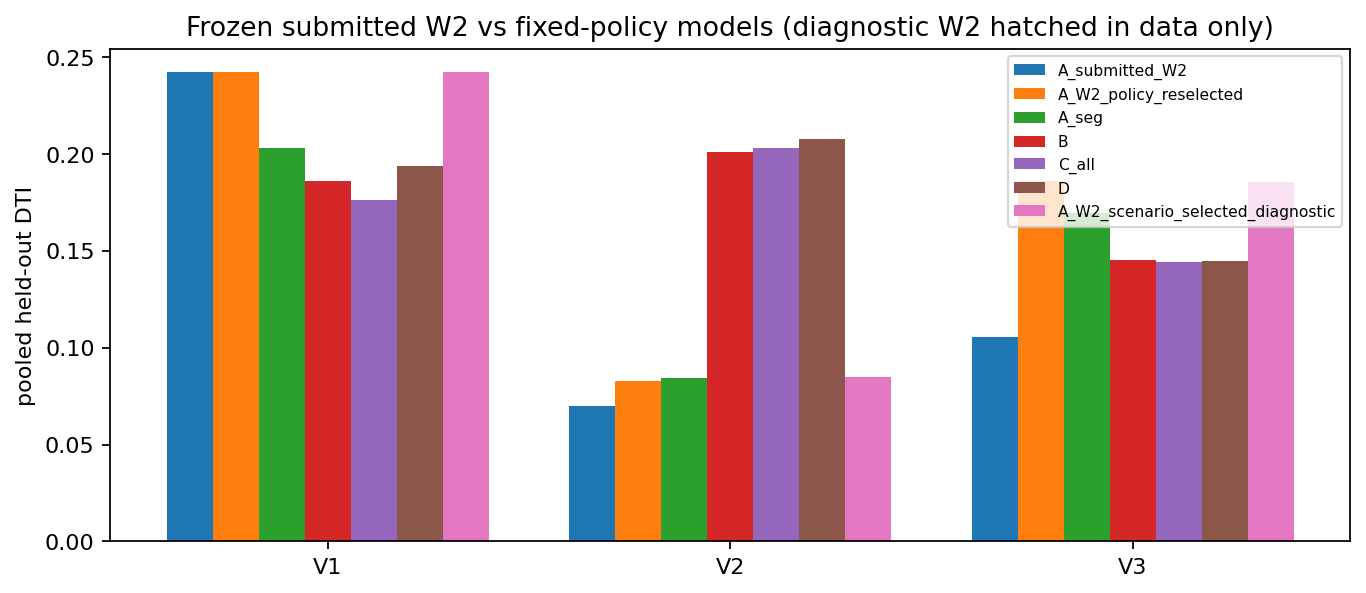

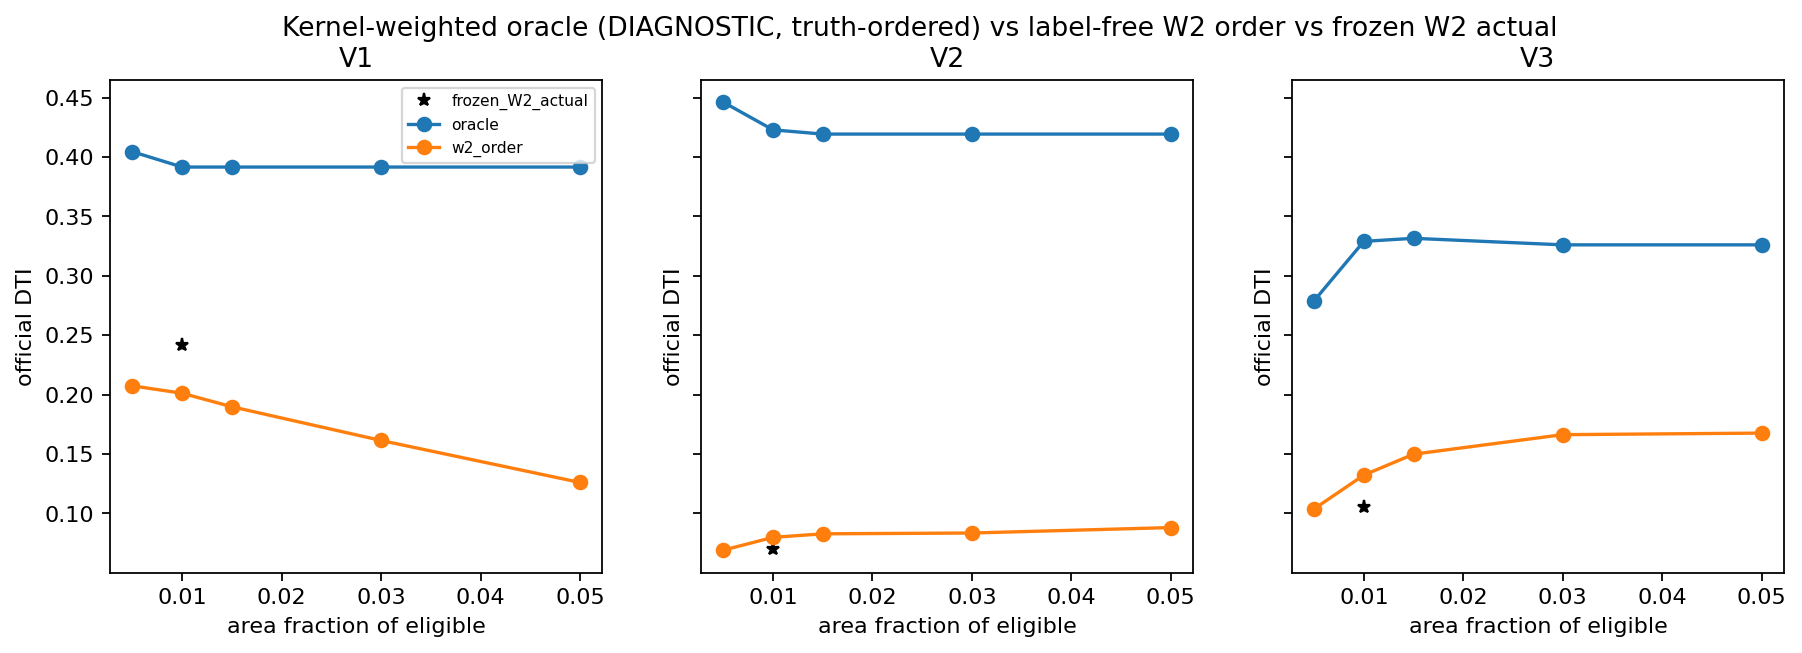

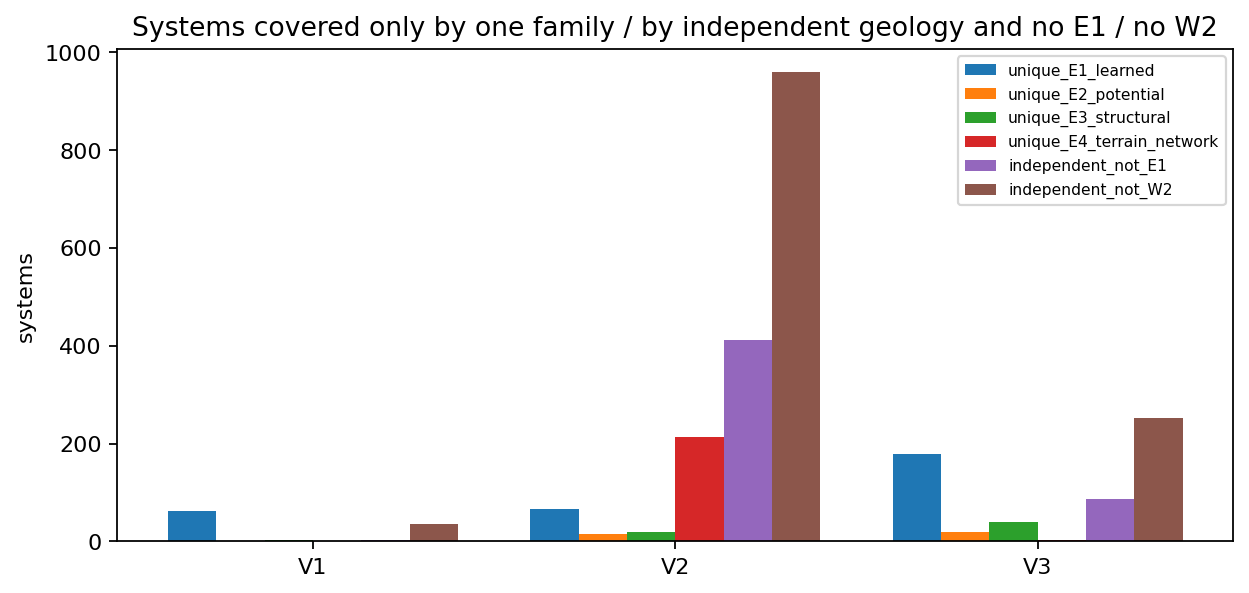

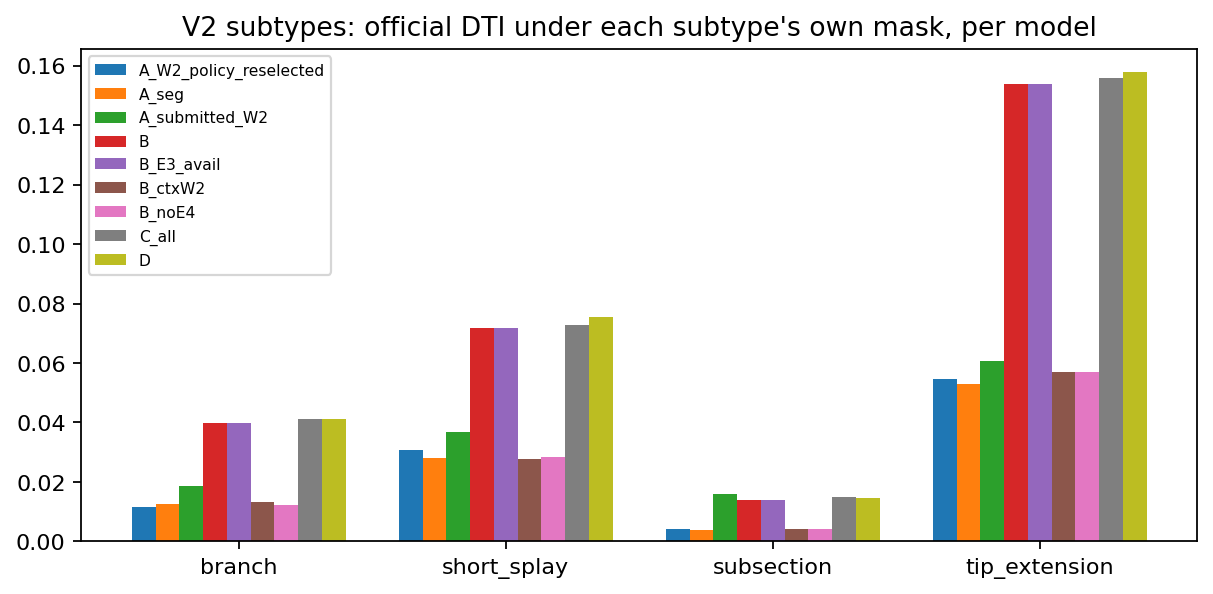

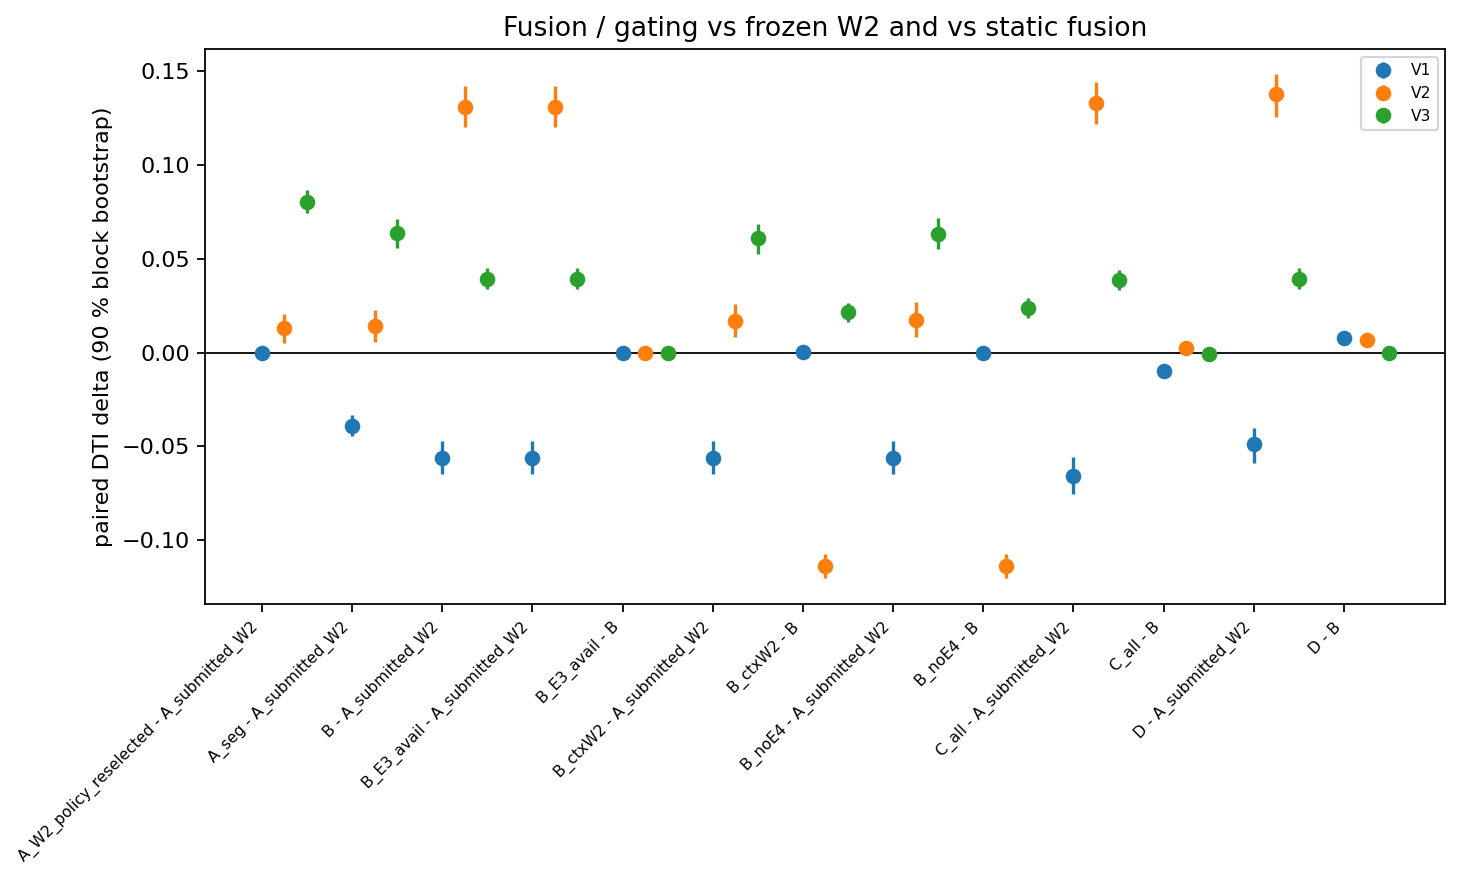

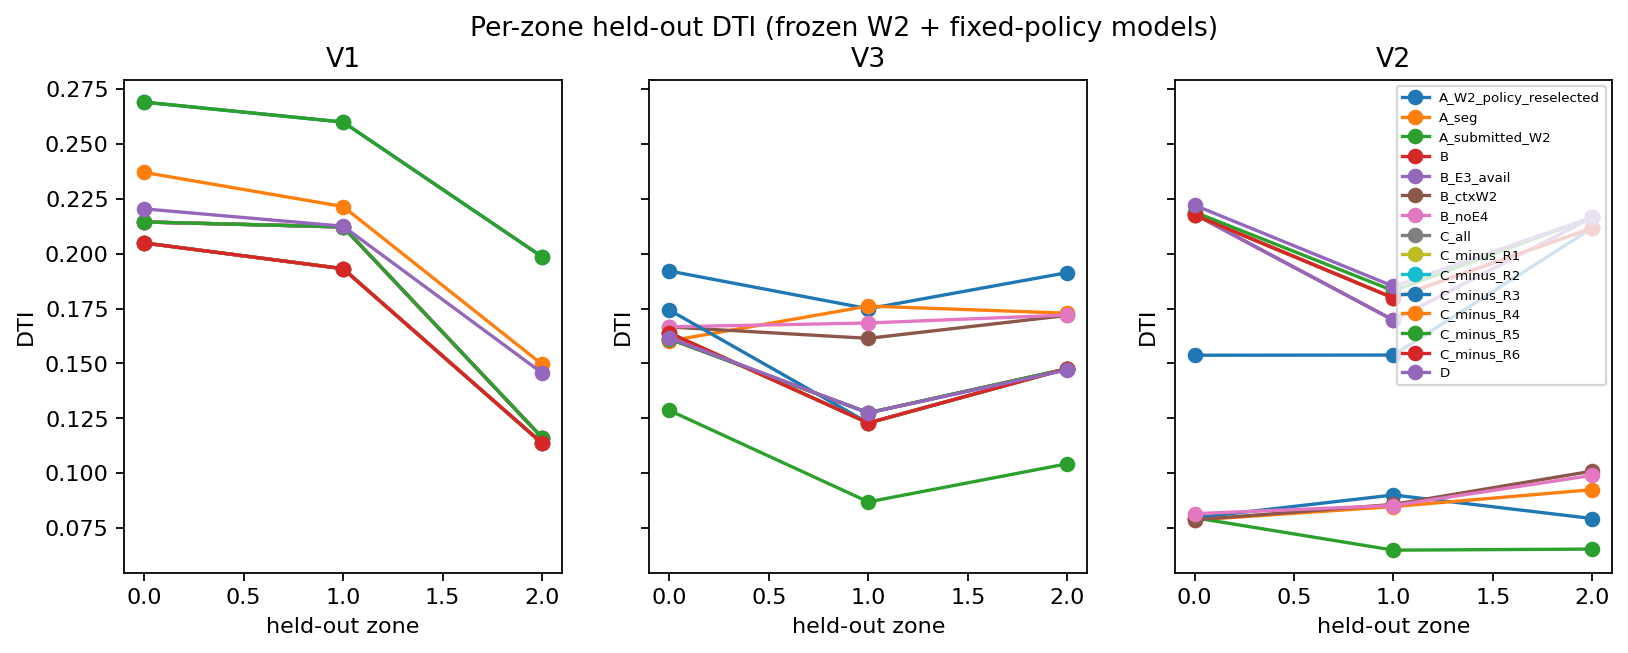

# Execution status

Code rev `dgm.2-r1`, commit `83da80a3b01208db6e750f0895b69bda73642c0d`, mode `FULL`.

Statuses: COMPLETE / REUSED_VALID_CACHE (measured), SKIPPED_BY_VALID_DECISION (a recorded decision), FAILED (exception), TESTS_FAILED, BLOCKED (technical gate), BLOCKED_UPSTREAM / NOT_EVALUATED (an upstream stage was invalid: nothing was concluded).

| stage | actual_status | required_dependencies | missing_outputs | failure_reason | affected_file | scientific_conclusion_allowed |
|---|---|---|---|---|---|---|
| 00_tests | COMPLETE |  |  |  |  | True |
| 01_attach | COMPLETE |  |  |  |  | True |
| 02_audit | COMPLETE | 01_attach |  |  |  | True |
| 03_scenarios | REUSED_VALID_CACHE | 01_attach |  |  |  | True |
| 04_candidates | REUSED_VALID_CACHE | 00_tests;03_scenarios |  |  |  | True |
| 05_oracle | REUSED_VALID_CACHE | 04_candidates |  |  |  | True |
| 06_decision | REUSED_VALID_CACHE | 05_oracle |  |  |  | True |
| 07_experts | REUSED_VALID_CACHE | 04_candidates |  |  |  | True |
| 08_static | REUSED_VALID_CACHE | 05_oracle;07_experts |  |  |  | True |
| 09_rules | REUSED_VALID_CACHE | 08_static |  |  |  | True |
| 10_learned | REUSED_VALID_CACHE | 06_decision;08_static |  |  |  | True |
| 10b_compare | COMPLETE | 05_oracle;08_static |  |  |  | True |
| 11_deployment | COMPLETE | 10b_compare |  |  |  | True |
| 12_export | SKIPPED_BY_VALID_DECISION | 10b_compare |  | No new submission: the predeclared selection rule retained W2 on measured fixed-policy numbers (no fused model beats A_submitted_W2 on enough scenarios without a scenario / worst-zone drop). The reference file stays the submission factory's w2_champion GeoTIFF. |  | True |



# Scientific findings

CONFIRMED = measured by this run's valid stages. INFERRED = interpretation. Offline numbers are cross-fitted estimates, not leaderboard scores; the public W2 score 0.0942 is an external benchmark only.

### 1. Does the new candidate pool recover fault systems W2 misses?

* CONFIRMED V1: unified pool covers 0.7750 of 120 systems; frozen submitted W2 recovers 0.1667; covered and not recovered by W2 = see candidates/unique_systems.csv
* CONFIRMED V2: unified pool covers 0.8941 of 1180 systems; frozen submitted W2 recovers 0.0797; covered and not recovered by W2 = see candidates/unique_systems.csv
* CONFIRMED V3: unified pool covers 0.6542 of 616 systems; frozen submitted W2 recovers 0.0471; covered and not recovered by W2 = see candidates/unique_systems.csv

### 2. Which expert families provide genuinely unique recovery?

| scenario | n_systems | unique_E1_learned | unique_E2_potential | unique_E3_structural | unique_E4_terrain_network | evaluated_E2_potential | evaluated_E3_structural | evaluated_E4_terrain_network | independent_not_E1 | independent_not_W2 |
|---|---|---|---|---|---|---|---|---|---|---|
| V1 | 120 | 63 | 0 | 3 | 0 | True | True | True | 3 | 36 |
| V2 | 1180 | 66 | 15 | 20 | 214 | True | True | True | 411 | 959 |
| V3 | 616 | 178 | 20 | 40 | 2 | True | True | True | 86 | 252 |

Geology status: **EVALUATED**, unique coverage under the predeclared rule: **True** (None = no independent family evaluated).
INFERRED caveat: potential-field gradients and G02 layers are also W2 inputs; only systems no E1 source covers count as unique gains.
G02 backfill: `{"status": "MISSING_NOT_BACKFILLED", "missing": ["geo_2", "disc_official_2"], "detail": "set backfill_missing_g02=True to compute only these units with the frozen G02 config"}`

### 3. Is V2 network completion a significant weakness of W2 under a fair comparison?

* CONFIRMED frozen submitted W2 DTI: V1 0.2422, V2 0.0699, V3 0.1057 (one frozen policy for all three; public 0.0942).

V2 by subtype (official components under each subtype's own mask where 10b ran; geometric coverage otherwise):

| subtype | model | tp_w | fp_w | fn_w | n_truth | dti | recovered_share | recovery_gain_vs_ref | dti_gain_vs_ref | n_events | truth_length_km | inventory_coverage | w2_recovered_share | coverage_E1_learned | coverage_E2_potential | coverage_E3_structural | coverage_E4_terrain_network |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| branch | A_W2_policy_reselected | 367.3145 | 152215.3356 | 1525.6855 | 1893 | 0.0115 | 0.2093 | 0.1589 | -0.0072 | 258 | 212.0160 | 0.8915 | 0.0504 | 0.5698 | 0.3682 | 0.3566 | 0.8178 |
| branch | A_seg | 578.4547 | 219737.7410 | 1314.5453 | 1893 | 0.0127 | 0.3876 | 0.3372 | -0.0060 | 258 | 212.0160 | 0.8915 | 0.0504 | 0.5698 | 0.3682 | 0.3566 | 0.8178 |
| branch | A_submitted_W2 | 114.4851 | 22956.1751 | 1778.5149 | 1893 | 0.0187 | 0.0504 | 0.0000 | 0.0000 | 258 | 212.0160 | 0.8915 | 0.0504 | 0.5698 | 0.3682 | 0.3566 | 0.8178 |
| branch | B | 659.8397 | 74413.2932 | 1233.1603 | 1893 | 0.0399 | 0.4690 | 0.4186 | 0.0212 | 258 | 212.0160 | 0.8915 | 0.0504 | 0.5698 | 0.3682 | 0.3566 | 0.8178 |
| branch | B_E3_avail | 659.8397 | 74413.2932 | 1233.1603 | 1893 | 0.0399 | 0.4690 | 0.4186 | 0.0212 | 258 | 212.0160 | 0.8915 | 0.0504 | 0.5698 | 0.3682 | 0.3566 | 0.8178 |
| branch | B_ctxW2 | 526.9950 | 189309.3842 | 1366.0050 | 1893 | 0.0133 | 0.3566 | 0.3062 | -0.0053 | 258 | 212.0160 | 0.8915 | 0.0504 | 0.5698 | 0.3682 | 0.3566 | 0.8178 |
| branch | B_noE4 | 533.1553 | 211179.3646 | 1359.8447 | 1893 | 0.0122 | 0.3566 | 0.3062 | -0.0065 | 258 | 212.0160 | 0.8915 | 0.0504 | 0.5698 | 0.3682 | 0.3566 | 0.8178 |
| branch | C_all | 658.6306 | 72036.6480 | 1234.3694 | 1893 | 0.0410 | 0.4806 | 0.4302 | 0.0223 | 258 | 212.0160 | 0.8915 | 0.0504 | 0.5698 | 0.3682 | 0.3566 | 0.8178 |
| branch | D | 681.6084 | 74305.7133 | 1211.3916 | 1893 | 0.0413 | 0.4961 | 0.4457 | 0.0226 | 258 | 212.0160 | 0.8915 | 0.0504 | 0.5698 | 0.3682 | 0.3566 | 0.8178 |
| short_splay | A_W2_policy_reselected | 1052.1963 | 151722.8911 | 3758.8037 | 4811 | 0.0306 | 0.2536 | 0.1697 | -0.0064 | 548 | 538.8320 | 0.8613 | 0.0839 | 0.5931 | 0.2774 | 0.2993 | 0.6971 |
| short_splay | A_seg | 1339.4435 | 219134.3533 | 3471.5565 | 4811 | 0.0279 | 0.3504 | 0.2664 | -0.0090 | 548 | 538.8320 | 0.8613 | 0.0839 | 0.5931 | 0.2774 | 0.2993 | 0.6971 |
| short_splay | A_submitted_W2 | 313.0594 | 22799.2832 | 4497.9406 | 4811 | 0.0370 | 0.0839 | 0.0000 | 0.0000 | 548 | 538.8320 | 0.8613 | 0.0839 | 0.5931 | 0.2774 | 0.2993 | 0.6971 |
| short_splay | B | 1355.0622 | 73852.9106 | 3455.9378 | 4811 | 0.0717 | 0.3832 | 0.2993 | 0.0348 | 548 | 538.8320 | 0.8613 | 0.0839 | 0.5931 | 0.2774 | 0.2993 | 0.6971 |
| short_splay | B_E3_avail | 1355.0622 | 73852.9106 | 3455.9378 | 4811 | 0.0717 | 0.3832 | 0.2993 | 0.0348 | 548 | 538.8320 | 0.8613 | 0.0839 | 0.5931 | 0.2774 | 0.2993 | 0.6971 |
| short_splay | B_ctxW2 | 1162.0732 | 188822.2415 | 3648.9268 | 4811 | 0.0278 | 0.3102 | 0.2263 | -0.0092 | 548 | 538.8320 | 0.8613 | 0.0839 | 0.5931 | 0.2774 | 0.2993 | 0.6971 |
| short_splay | B_noE4 | 1309.9296 | 210552.2429 | 3501.0704 | 4811 | 0.0283 | 0.3485 | 0.2646 | -0.0086 | 548 | 538.8320 | 0.8613 | 0.0839 | 0.5931 | 0.2774 | 0.2993 | 0.6971 |
| short_splay | C_all | 1338.9147 | 71495.6140 | 3472.0853 | 4811 | 0.0727 | 0.3777 | 0.2938 | 0.0357 | 548 | 538.8320 | 0.8613 | 0.0839 | 0.5931 | 0.2774 | 0.2993 | 0.6971 |
| short_splay | D | 1421.6374 | 73706.7027 | 3389.3626 | 4811 | 0.0753 | 0.4051 | 0.3212 | 0.0384 | 548 | 538.8320 | 0.8613 | 0.0839 | 0.5931 | 0.2774 | 0.2993 | 0.6971 |
| subsection | A_W2_policy_reselected | 124.6327 | 152425.8825 | 272.3673 | 397 | 0.0040 | 0.3750 | 0.1562 | -0.0120 | 32 | 44.4640 | 0.9375 | 0.2188 | 0.6250 | 0.3125 | 0.3125 | 1.0000 |
| subsection | A_seg | 173.2519 | 220076.8586 | 223.7481 | 397 | 0.0039 | 0.6250 | 0.4062 | -0.0121 | 32 | 44.4640 | 0.9375 | 0.2188 | 0.6250 | 0.3125 | 0.3125 | 1.0000 |
| subsection | A_submitted_W2 | 79.0397 | 22992.8085 | 317.9603 | 397 | 0.0160 | 0.2188 | 0.0000 | 0.0000 | 32 | 44.4640 | 0.9375 | 0.2188 | 0.6250 | 0.3125 | 0.3125 | 1.0000 |
| subsection | B | 211.7062 | 74775.1587 | 185.2938 | 397 | 0.0138 | 0.7500 | 0.5312 | -0.0022 | 32 | 44.4640 | 0.9375 | 0.2188 | 0.6250 | 0.3125 | 0.3125 | 1.0000 |
| subsection | B_E3_avail | 211.7062 | 74775.1587 | 185.2938 | 397 | 0.0138 | 0.7500 | 0.5312 | -0.0022 | 32 | 44.4640 | 0.9375 | 0.2188 | 0.6250 | 0.3125 | 0.3125 | 1.0000 |
| subsection | B_ctxW2 | 161.5325 | 189611.6866 | 235.4675 | 397 | 0.0042 | 0.5312 | 0.3125 | -0.0118 | 32 | 44.4640 | 0.9375 | 0.2188 | 0.6250 | 0.3125 | 0.3125 | 1.0000 |
| subsection | B_noE4 | 172.2541 | 211474.5286 | 224.7459 | 397 | 0.0040 | 0.5938 | 0.3750 | -0.0120 | 32 | 44.4640 | 0.9375 | 0.2188 | 0.6250 | 0.3125 | 0.3125 | 1.0000 |
| subsection | C_all | 223.6180 | 72383.9409 | 173.3820 | 397 | 0.0151 | 0.8125 | 0.5938 | -0.0010 | 32 | 44.4640 | 0.9375 | 0.2188 | 0.6250 | 0.3125 | 0.3125 | 1.0000 |
| subsection | D | 222.1918 | 74676.3540 | 174.8082 | 397 | 0.0145 | 0.7812 | 0.5625 | -0.0015 | 32 | 44.4640 | 0.9375 | 0.2188 | 0.6250 | 0.3125 | 0.3125 | 1.0000 |
| tip_extension | A_W2_policy_reselected | 2082.9061 | 151196.4666 | 7118.0939 | 9201 | 0.0548 | 0.2339 | 0.1520 | -0.0060 | 342 | 1030.5120 | 0.9444 | 0.0819 | 0.6170 | 0.2281 | 0.3158 | 0.8684 |
| tip_extension | A_seg | 2736.5704 | 218415.3835 | 6464.4296 | 9201 | 0.0530 | 0.3655 | 0.2836 | -0.0078 | 342 | 1030.5120 | 0.9444 | 0.0819 | 0.6170 | 0.2281 | 0.3158 | 0.8684 |
| tip_extension | A_submitted_W2 | 731.6982 | 22599.5330 | 8469.3018 | 9201 | 0.0608 | 0.0819 | 0.0000 | 0.0000 | 342 | 1030.5120 | 0.9444 | 0.0819 | 0.6170 | 0.2281 | 0.3158 | 0.8684 |
| tip_extension | B | 3476.6130 | 72783.7014 | 5724.3870 | 9201 | 0.1537 | 0.5556 | 0.4737 | 0.0929 | 342 | 1030.5120 | 0.9444 | 0.0819 | 0.6170 | 0.2281 | 0.3158 | 0.8684 |
| tip_extension | B_E3_avail | 3476.6130 | 72783.7014 | 5724.3870 | 9201 | 0.1537 | 0.5556 | 0.4737 | 0.0929 | 342 | 1030.5120 | 0.9444 | 0.0819 | 0.6170 | 0.2281 | 0.3158 | 0.8684 |
| tip_extension | B_ctxW2 | 2599.0305 | 188070.3530 | 6601.9695 | 9201 | 0.0571 | 0.3538 | 0.2719 | -0.0037 | 342 | 1030.5120 | 0.9444 | 0.0819 | 0.6170 | 0.2281 | 0.3158 | 0.8684 |
| tip_extension | B_noE4 | 2834.8302 | 209727.3330 | 6366.1698 | 9201 | 0.0568 | 0.3889 | 0.3070 | -0.0040 | 342 | 1030.5120 | 0.9444 | 0.0819 | 0.6170 | 0.2281 | 0.3158 | 0.8684 |
| tip_extension | C_all | 3446.8345 | 70403.0817 | 5754.1655 | 9201 | 0.1557 | 0.5556 | 0.4737 | 0.0949 | 342 | 1030.5120 | 0.9444 | 0.0819 | 0.6170 | 0.2281 | 0.3158 | 0.8684 |
| tip_extension | D | 3565.6291 | 72593.6039 | 5635.3709 | 9201 | 0.1578 | 0.5760 | 0.4942 | 0.0970 | 342 | 1030.5120 | 0.9444 | 0.0819 | 0.6170 | 0.2281 | 0.3158 | 0.8684 |

Context fairness: `B_ctxW2` scores E4 with W2's own known context and drops tips-only candidates; `B - B_ctxW2` is the share of any V2 gain due to the additional retained-network context, not to fusion (V1 +0.0000 [-0.0000, +0.0001] P(>0)=0.73; V2 -0.1141 [-0.1204, -0.1075] P(>0)=0.00; V3 +0.0216 [+0.0164, +0.0267] P(>0)=1.00).
INFERRED: a low V2 relative to V1 / V3 indicates a network-completion weakness of W2 only if B_ctxW2 (no extra context) also beats it on V2.

### 4. Is candidate generation or candidate ranking the dominant limitation?

**RANKING_LIMITED** (scenarios disagree: [])

| scenario | verdict | pool_coverage | w2_recovered | gap | n_systems | independent_not_E1 | independent_share |
|---|---|---|---|---|---|---|---|
| V1 | RANKING_LIMITED | 0.7750 | 0.1667 | 0.6083 | 120 | 3 | 0.0250 |
| V2 | RANKING_LIMITED | 0.8941 | 0.0797 | 0.8144 | 1180 | 411 | 0.3483 |
| V3 | RANKING_LIMITED | 0.6542 | 0.0471 | 0.6071 | 616 | 86 | 0.1396 |

M7 vs X2 under one definition:

| scenario | pool | system_coverage | length_coverage | ranking_limited_length_share | generation_limited_length_share |
|---|---|---|---|---|---|
| V1 | label_free | 0.4083 | 0.4145 | 0.4052 | 0.5948 |
| V1 | fam:E1_learned | 0.8500 | 0.7792 | 0.8607 | 0.1393 |
| V1 | inventory | 0.7750 | 0.7207 | 0.7822 | 0.2178 |
| V2 | label_free | 0.4636 | 0.4610 | 0.5061 | 0.4939 |
| V2 | fam:E1_learned | 0.5958 | 0.5686 | 0.5816 | 0.4184 |
| V2 | inventory | 0.8941 | 0.8428 | 0.8941 | 0.1059 |
| V3 | label_free | 0.4448 | 0.4254 | 0.4355 | 0.5645 |
| V3 | fam:E1_learned | 0.5828 | 0.5714 | 0.6443 | 0.3557 |
| V3 | inventory | 0.6542 | 0.6215 | 0.6874 | 0.3126 |


### 5. Does static fusion improve official DTI?

B vs frozen W2: V1 -0.0562 [-0.0650, -0.0474] P(>0)=0.00; V2 +0.1311 [+0.1203, +0.1423] P(>0)=1.00; V3 +0.0393 [+0.0341, +0.0451] P(>0)=1.00
B vs A_seg (fusion alone): see gating/effect_decomposition.csv

### 6. Does geological routing add incremental value?

C_all vs B: V1 -0.0097 [-0.0122, -0.0074] P(>0)=0.00; V2 +0.0022 [-0.0002, +0.0049] P(>0)=0.93; V3 -0.0006 [-0.0024, +0.0012] P(>0)=0.25
Per-rule ablations: gating/model_summary.csv (C_minus_*).

### 7. Does the learned GeoMoE outperform simpler alternatives?

D vs B: V1 +0.0076 [+0.0041, +0.0110] P(>0)=1.00; V2 +0.0067 [+0.0041, +0.0097] P(>0)=1.00; V3 -0.0000 [-0.0003, +0.0003] P(>0)=0.41

### 8. Does the improvement survive geographic validation?

V3 (fixed policy): B 0.1450 vs frozen W2 0.1057; worst zone 0.1275 vs 0.0869

### 9. Can the best model be deployed consistently across the whole region?

| construction | model | zone | rep | frac | tp_w | fp_w | fn_w | n_truth | dti | area_frac_eligible | pooled_dti |
|---|---|---|---|---|---|---|---|---|---|---|---|
| zone_stitched | B | 0 | crest_1px | 0.0150 | 3336.9090 | 25333.3774 | 15370.0910 | 18707 | 0.1612 | 0.0150 | 0.1450 |
| fold_average | B | 0 | crest_1px | 0.0150 | 3341.8882 | 25330.6557 | 15365.1118 | 18707 | 0.1614 | 0.0150 | 0.1433 |
| footprint_rank | B | 0 | crest_1px | 0.0150 | 3344.6962 | 25331.1464 | 15362.3038 | 18707 | 0.1616 | 0.0150 | 0.1459 |
| zone_stitched | B | 1 | crest_1px | 0.0150 | 2847.3955 | 20801.2935 | 19160.6045 | 22008 | 0.1275 | 0.0150 | 0.1450 |
| fold_average | B | 1 | crest_1px | 0.0150 | 2844.1226 | 20788.1460 | 19163.8774 | 22008 | 0.1274 | 0.0150 | 0.1433 |
| footprint_rank | B | 1 | crest_1px | 0.0150 | 2869.9068 | 20710.1056 | 19138.0932 | 22008 | 0.1286 | 0.0150 | 0.1459 |
| zone_stitched | B | 2 | crest_1px | 0.0150 | 3157.8789 | 23157.8050 | 17021.1211 | 20179 | 0.1475 | 0.0150 | 0.1450 |
| fold_average | B | 2 | crest_1px | 0.0150 | 3048.5877 | 23234.9120 | 17130.4123 | 20179 | 0.1425 | 0.0150 | 0.1433 |
| footprint_rank | B | 2 | crest_1px | 0.0150 | 3186.4628 | 23158.8399 | 16992.5372 | 20179 | 0.1488 | 0.0150 | 0.1459 |

Decision: `{"fold_average": {"pooled_dti": 0.14332125148960048, "delta_vs_zone_stitched": -0.0016488647857618444, "min_spearman": 0.9731519299240223, "equivalent": false}, "footprint_rank": {"pooled_dti": 0.1458990122757667, "delta_vs_zone_stitched": 0.0009288960004043834, "min_spearman": 0.941932740558019, "equivalent": false}, "zone_stitched": {"pooled_dti": 0.14497011627536233, "delta_vs_zone_stitched": 0.0, "min_spearman": 1.0, "equivalent": true}}`

### 10. Is there a technically valid GeoTIFF worth testing publicly?

* `None` **NOT_SELECTED** (none), model RETAIN_W2, sha256 `None`

## Next action

**Train a candidate-level ranker restricted to the systems the independent families uniquely cover (the gate did not convert that coverage).** (coverage verdict RANKING_LIMITED, independent geology adds unique systems)


# Leaderboard recommendation

Public reference: W2 champion 0.0942 (one scored file).

No file to upload. Selection status: RETAIN_W2. No new submission: the predeclared selection rule retained W2 on measured fixed-policy numbers (no fused model beats A_submitted_W2 on enough scenarios without a scenario / worst-zone drop). The reference file stays the submission factory's w2_champion GeoTIFF.


# Next action

Train a candidate-level ranker restricted to the systems the independent families uniquely cover (the gate did not convert that coverage).

Evidence: coverage verdict RANKING_LIMITED, independent geology adds unique systems.

Derived by `gems_bench.geomoe.decide.next_action` (first matching rule of a fixed tree).



Coverage verdict: RANKING_LIMITED {'V1': 'RANKING_LIMITED', 'V2': 'RANKING_LIMITED', 'V3': 'RANKING_LIMITED'} | geology EVALUATED unique=True
Inspect: audit/stage_integrity.csv, candidates/oracle_coverage.csv, audit/candidate_bottleneck_reconciliation.csv, validation/frozen_w2_baseline.csv, validation/v2_coverage_by_subtype.csv, reports/EXECUTION_STATUS.md
Selection: RETAIN_W2 -> RETAIN_W2
  NOT_SELECTED: None sha256 None
Drive: /content/drive/MyDrive/GEMS_2/outputs/discovery_geomoe


In [10]:
G.s14_integrity(); G.s13_reports()
show('audit/stage_integrity.csv', ['stage', 'actual_status', 'missing_outputs', 'failure_reason', 'affected_file', 'scientific_conclusion_allowed'])
for f in ('baseline_comparison', 'oracle_vs_actual', 'unique_geology_recovery', 'v2_fault_subtypes', 'gating_comparison', 'geographic_robustness'):
    p = OUT / 'figures' / f'{f}.png'
    if p.exists(): display(Image(str(p)))
for r in ('EXECUTION_STATUS', 'SCIENTIFIC_FINDINGS', 'LEADERBOARD_RECOMMENDATION', 'NEXT_ACTION'):
    display(Markdown((OUT / f'reports/{r}.md').read_text()))
G.final_message()